# Recorded final-test results

All performance values and confidence intervals come from the closed evaluation JSON artifacts. This notebook reads those artifacts and existing prediction exports; it does not fit models, reopen the final test, or compute performance metrics. The target is at least one selected satellite detection during the next seven days.

The temporal population excludes held-out blocks. Geographic results use the separately selected `strict_geo` models, whose features exclude cell climatology. Baseline choices are fixed by validation AP and retain their original probabilities; logistic regression and LightGBM use their recorded calibrated probabilities.

In [1]:
from IPython.display import Markdown, display
import pandas as pd

from bolivia_fire.figures import build_results_artifacts, show_results_figure

summary = build_results_artifacts()
print("Source: artifacts/evaluation/test_strict.json")
print(f"Temporal selection: {summary['figures']['temporal']['selected_model']}")
print(f"Geographic selection: {summary['figures']['geographic']['selected_model']}")
print(f"Example issue week: {summary['figures']['map']['issue_date']} (UTC)")

Source: artifacts/evaluation/test_strict.json
Temporal selection: lightgbm_08
Geographic selection: lightgbm_04
Example issue week: 2024-09-02 (UTC)


The table retains the recorded temporal AP and bootstrap endpoints. Differences use the uncalibrated best baseline selected on `val_select`. The summary JSON records the source path, source key, input checksum, probability version, plotted values, and captions.

In [2]:
pd.DataFrame([
    {
        "Model": row["label"],
        "AP": row["average_precision"],
        "95% CI lower": row["ap_interval"]["lower"],
        "95% CI upper": row["ap_interval"]["upper"],
        "AP difference vs baseline": row["paired_difference"],
    }
    for row in summary["figures"]["temporal"]["models"]
])

,Model,AP,95% CI lower,95% CI upper,AP difference vs baseline
0,Climatology,0.166677,0.105385,0.214274,0.000000
1,Persistence,0.143290,0.085345,0.186614,-0.023387
2,Logistic regression (calibrated),0.293042,0.195122,0.353043,0.126366
3,LightGBM (calibrated),0.323393,0.221655,0.382973,0.156716


## Temporal test and paired comparison

Temporal test, strict; 2023–2025. Original baseline probabilities; fitted candidates are calibrated. Points are recorded APs; differences subtract recorded APs on identical support. 95% paired calendar-month-block bootstrap intervals use 500 recorded replicates. Comparator: Climatology (chosen on val_select).

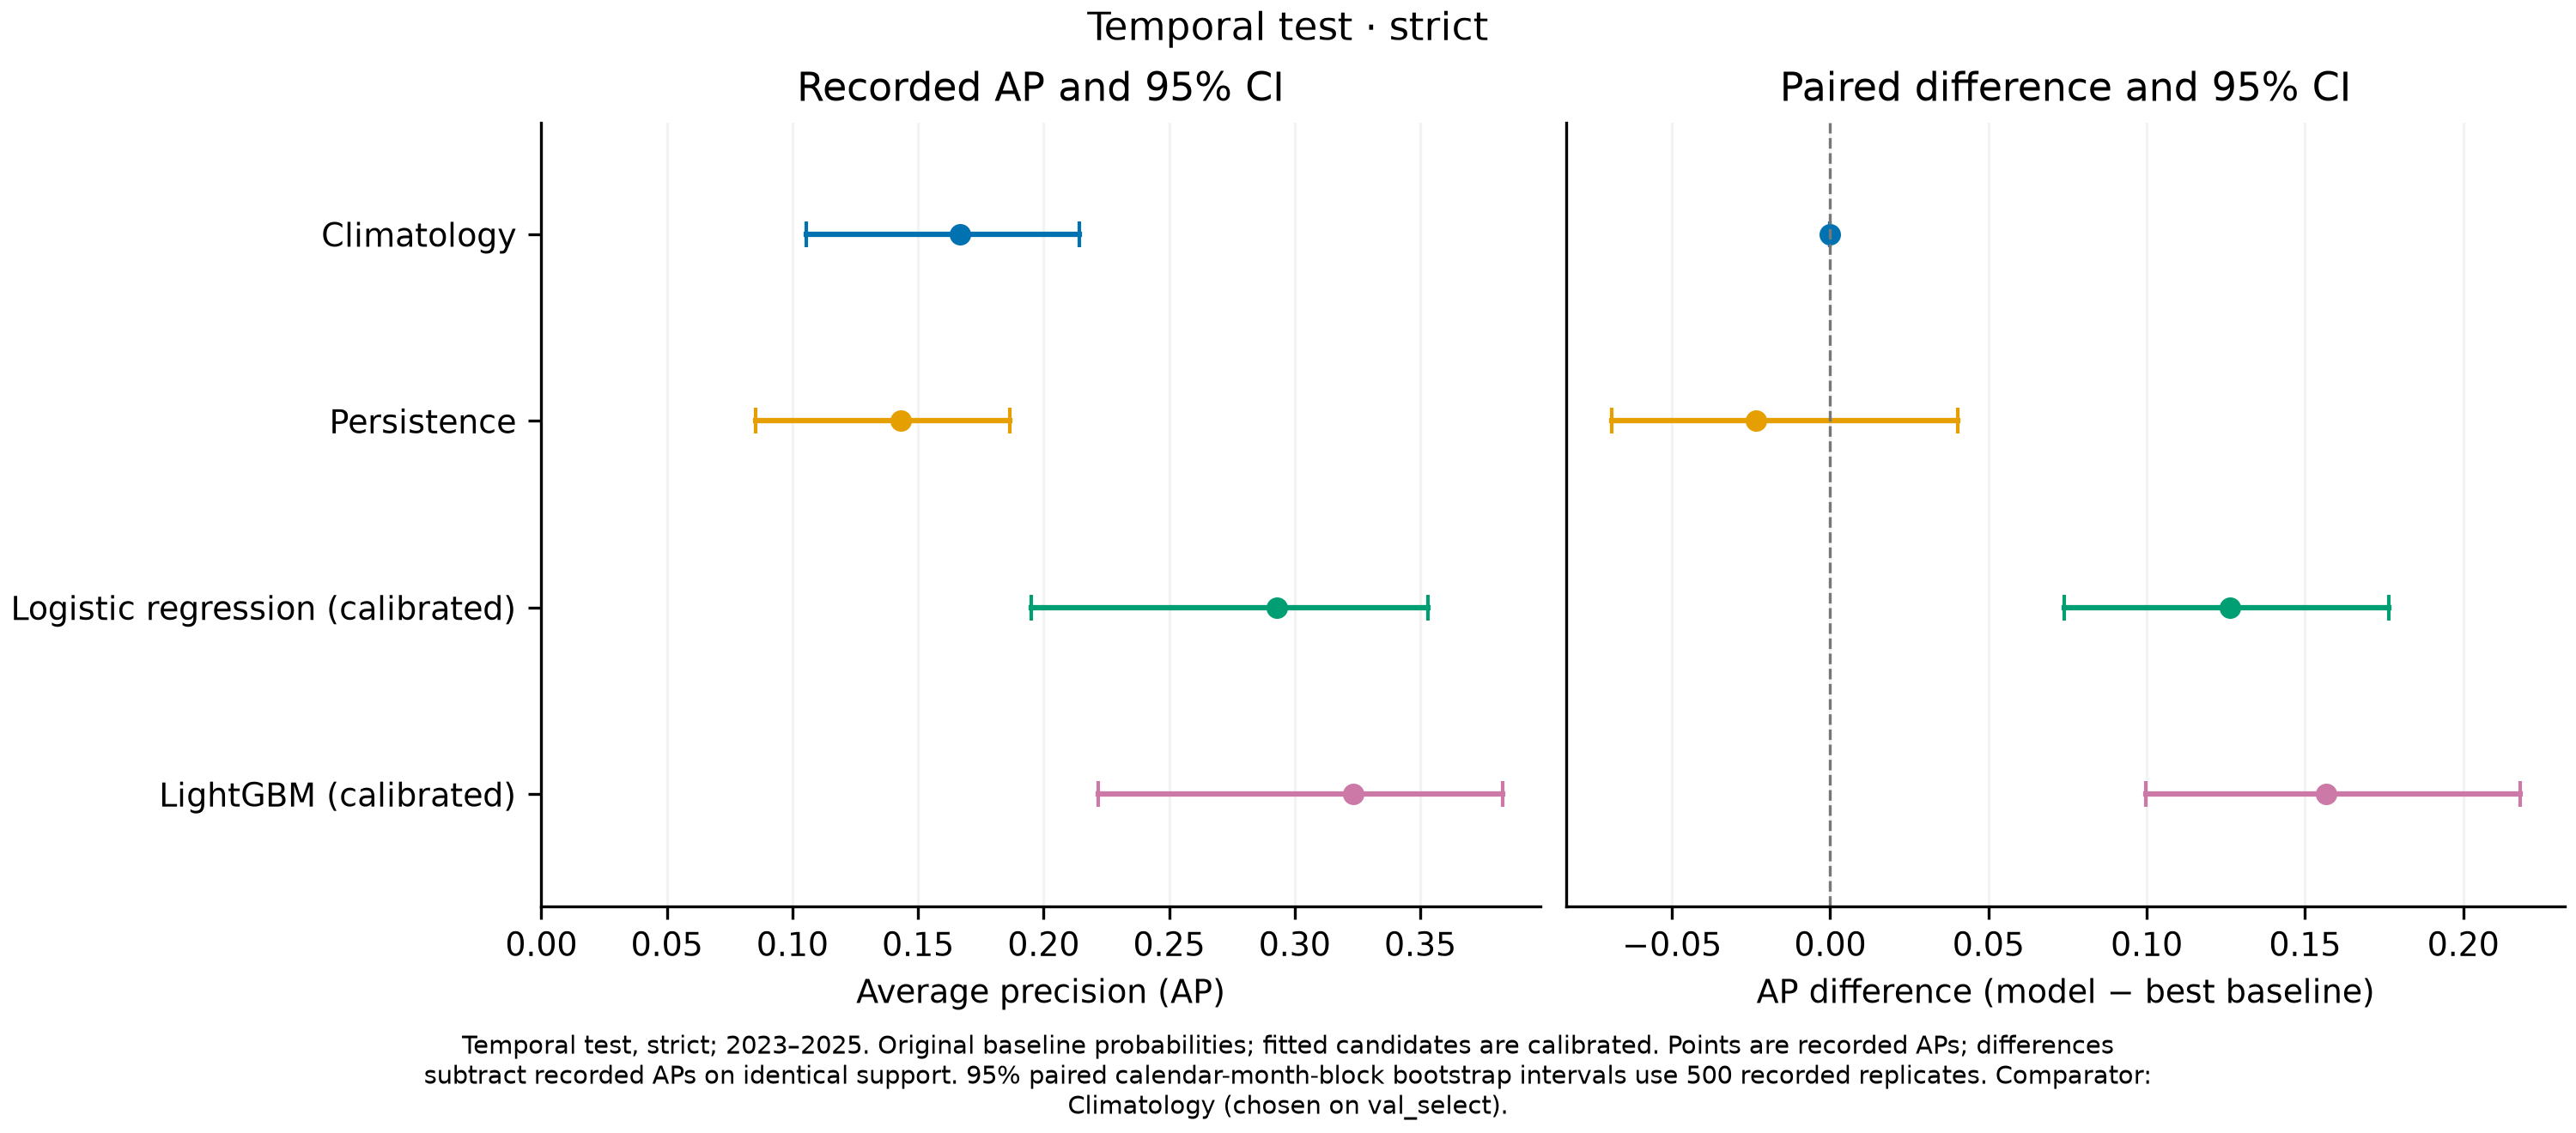

In [3]:
display(Markdown(summary["figures"]["temporal"]["caption"]))
show_results_figure("temporal")

## Reliability of the selected model and best baseline

Temporal test, 2023–2025. Recorded equal-frequency reliability bins; each point retains its recorded bin mass. The second panel expands the low-probability range; the dashed line is perfect reliability.

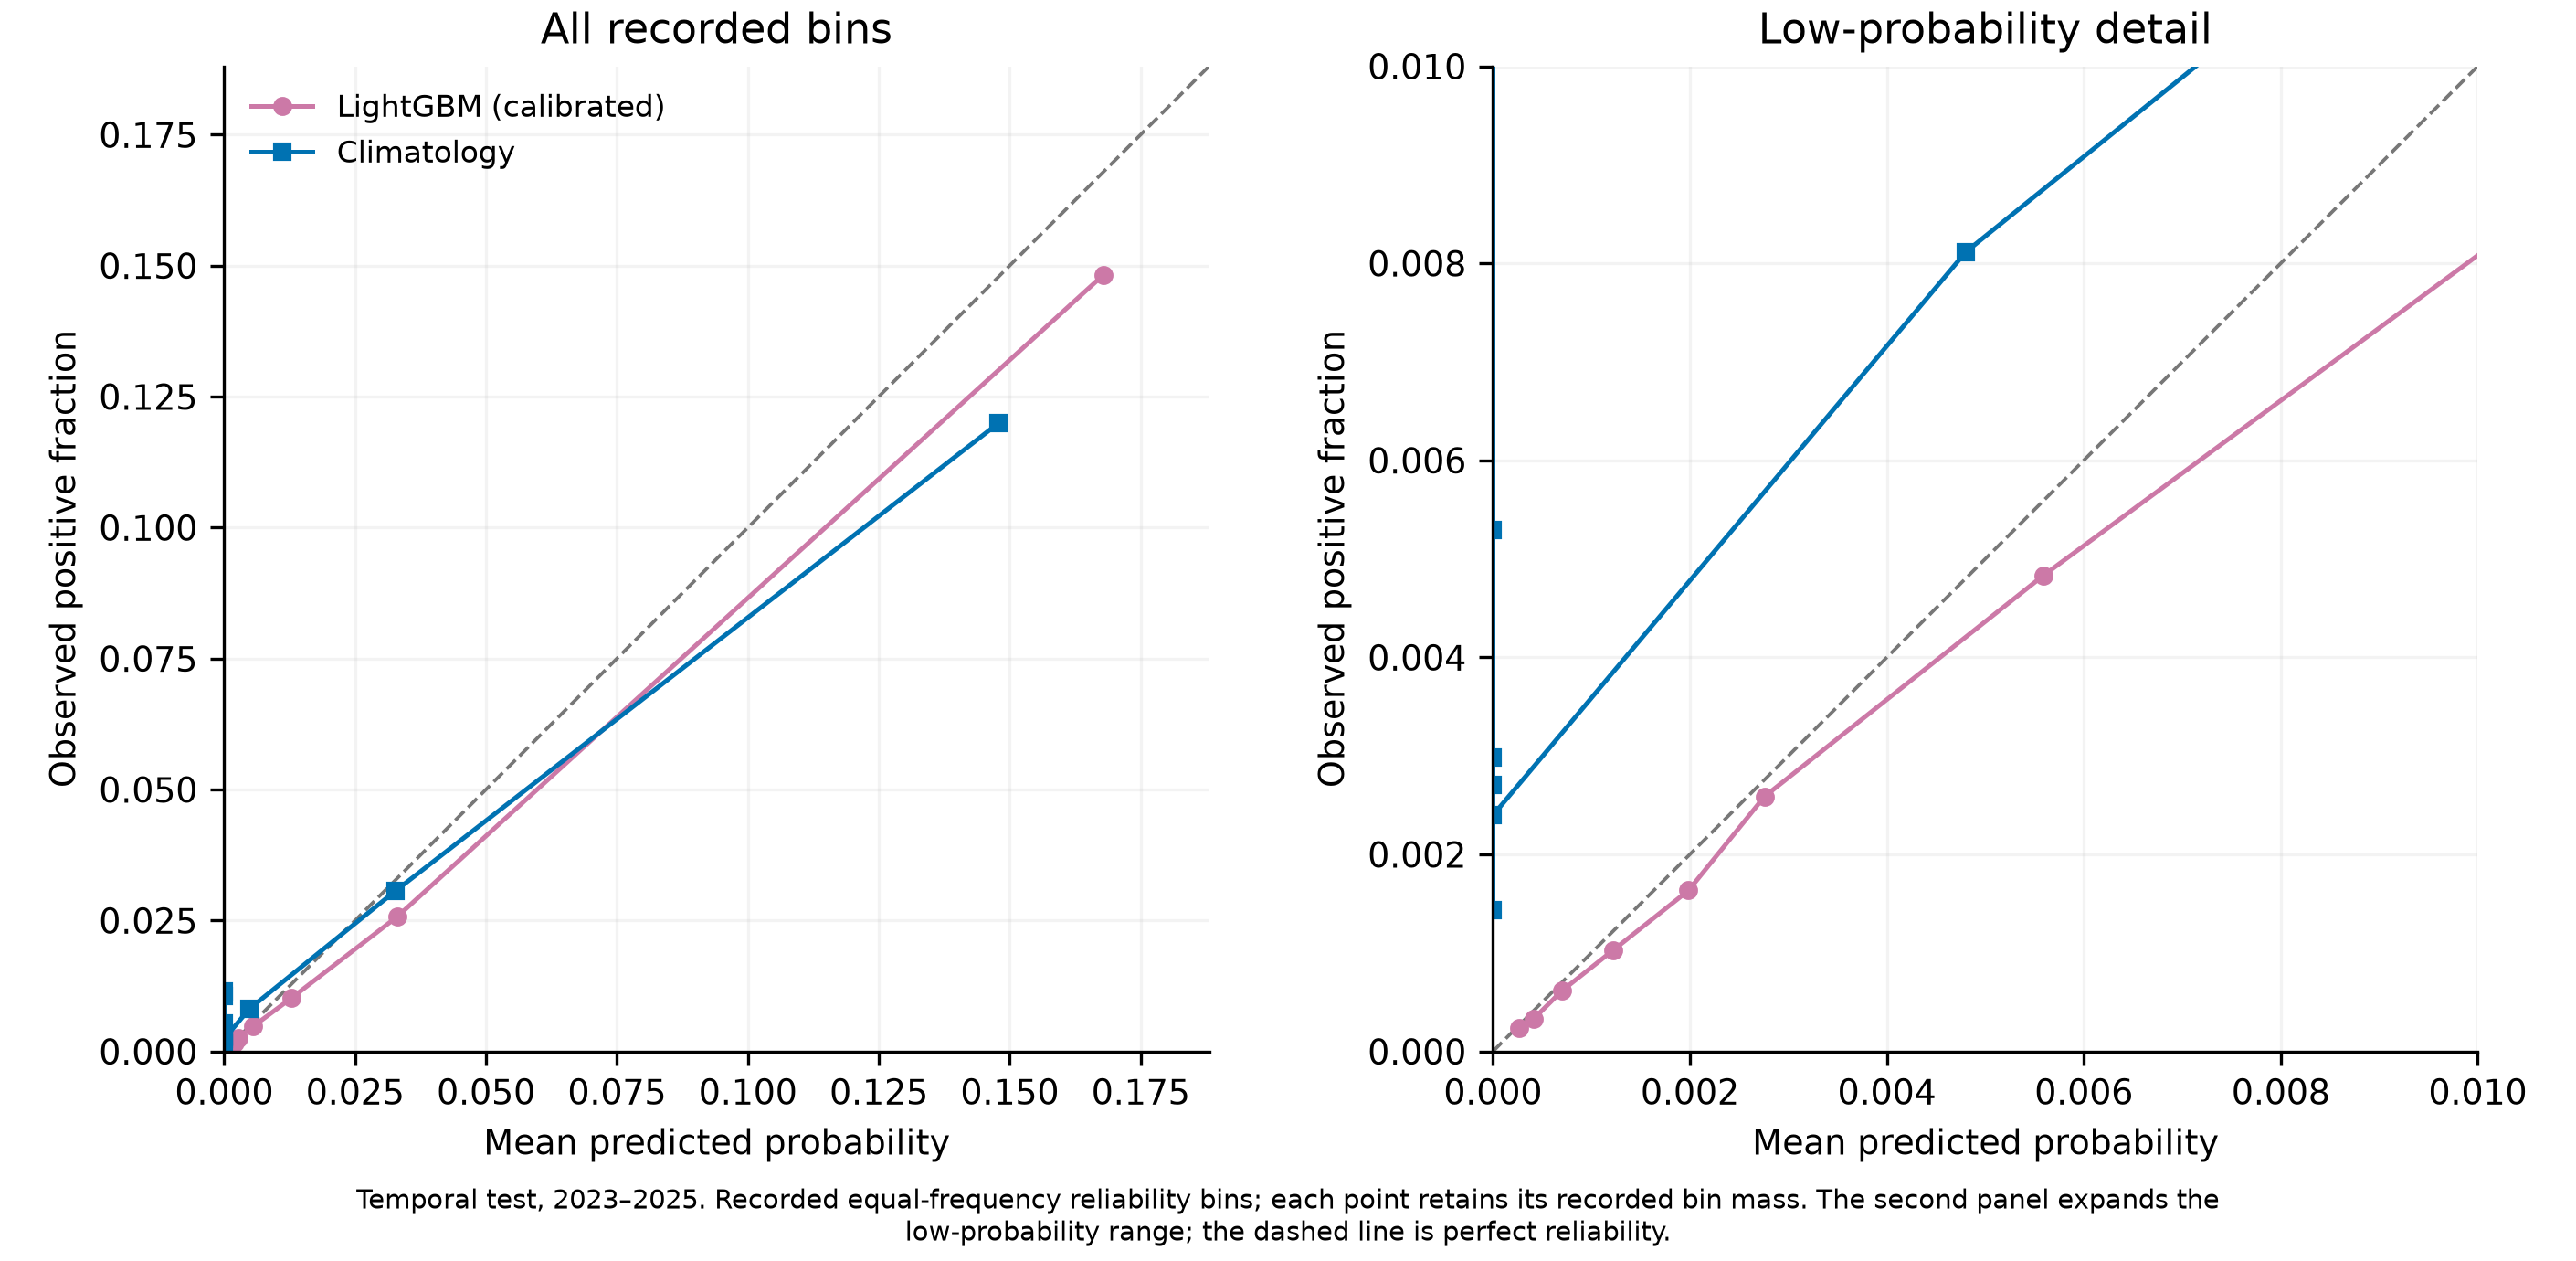

In [4]:
display(Markdown(summary["figures"]["reliability"]["caption"]))
show_results_figure("reliability")

## AP by test year

Temporal-test AP by issue year. Original baselines and calibrated fitted candidates; all values are recorded, with no annual intervals.

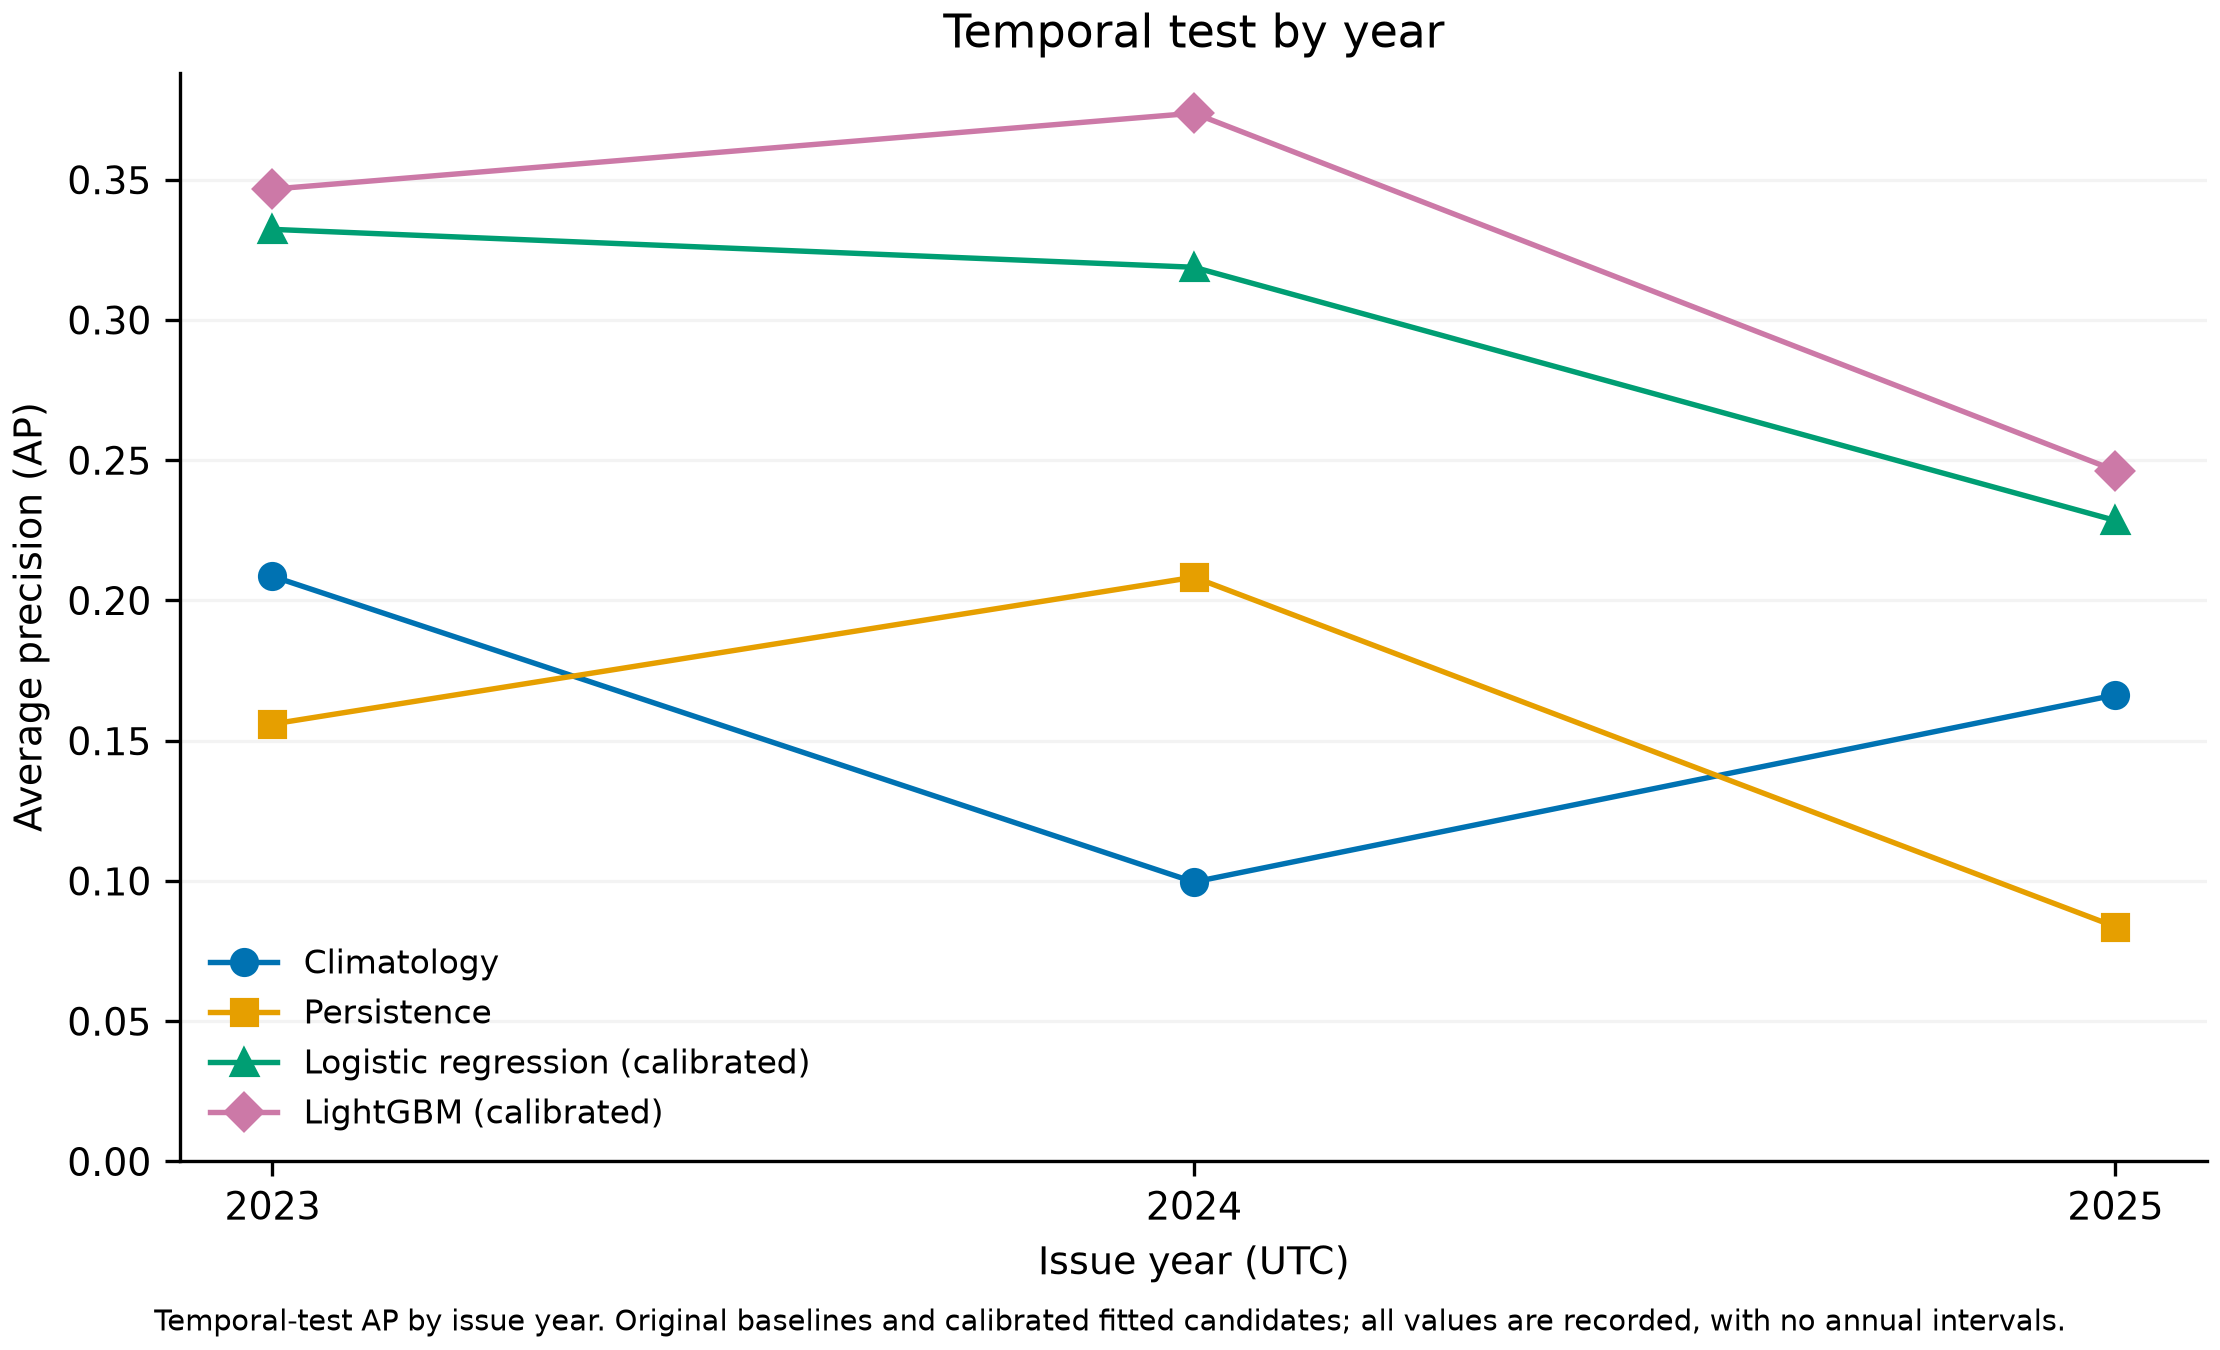

In [5]:
display(Markdown(summary["figures"]["per_year"]["caption"]))
show_results_figure("per_year")

## Geographic holdout and paired comparison

Geographic holdout, strict_geo; 2023–2025. Original baseline probabilities; fitted candidates are calibrated. Points are recorded APs; differences subtract recorded APs on identical support. 95% paired one-degree spatial-block bootstrap intervals use 500 recorded replicates. Comparator: Persistence (chosen on val_select).

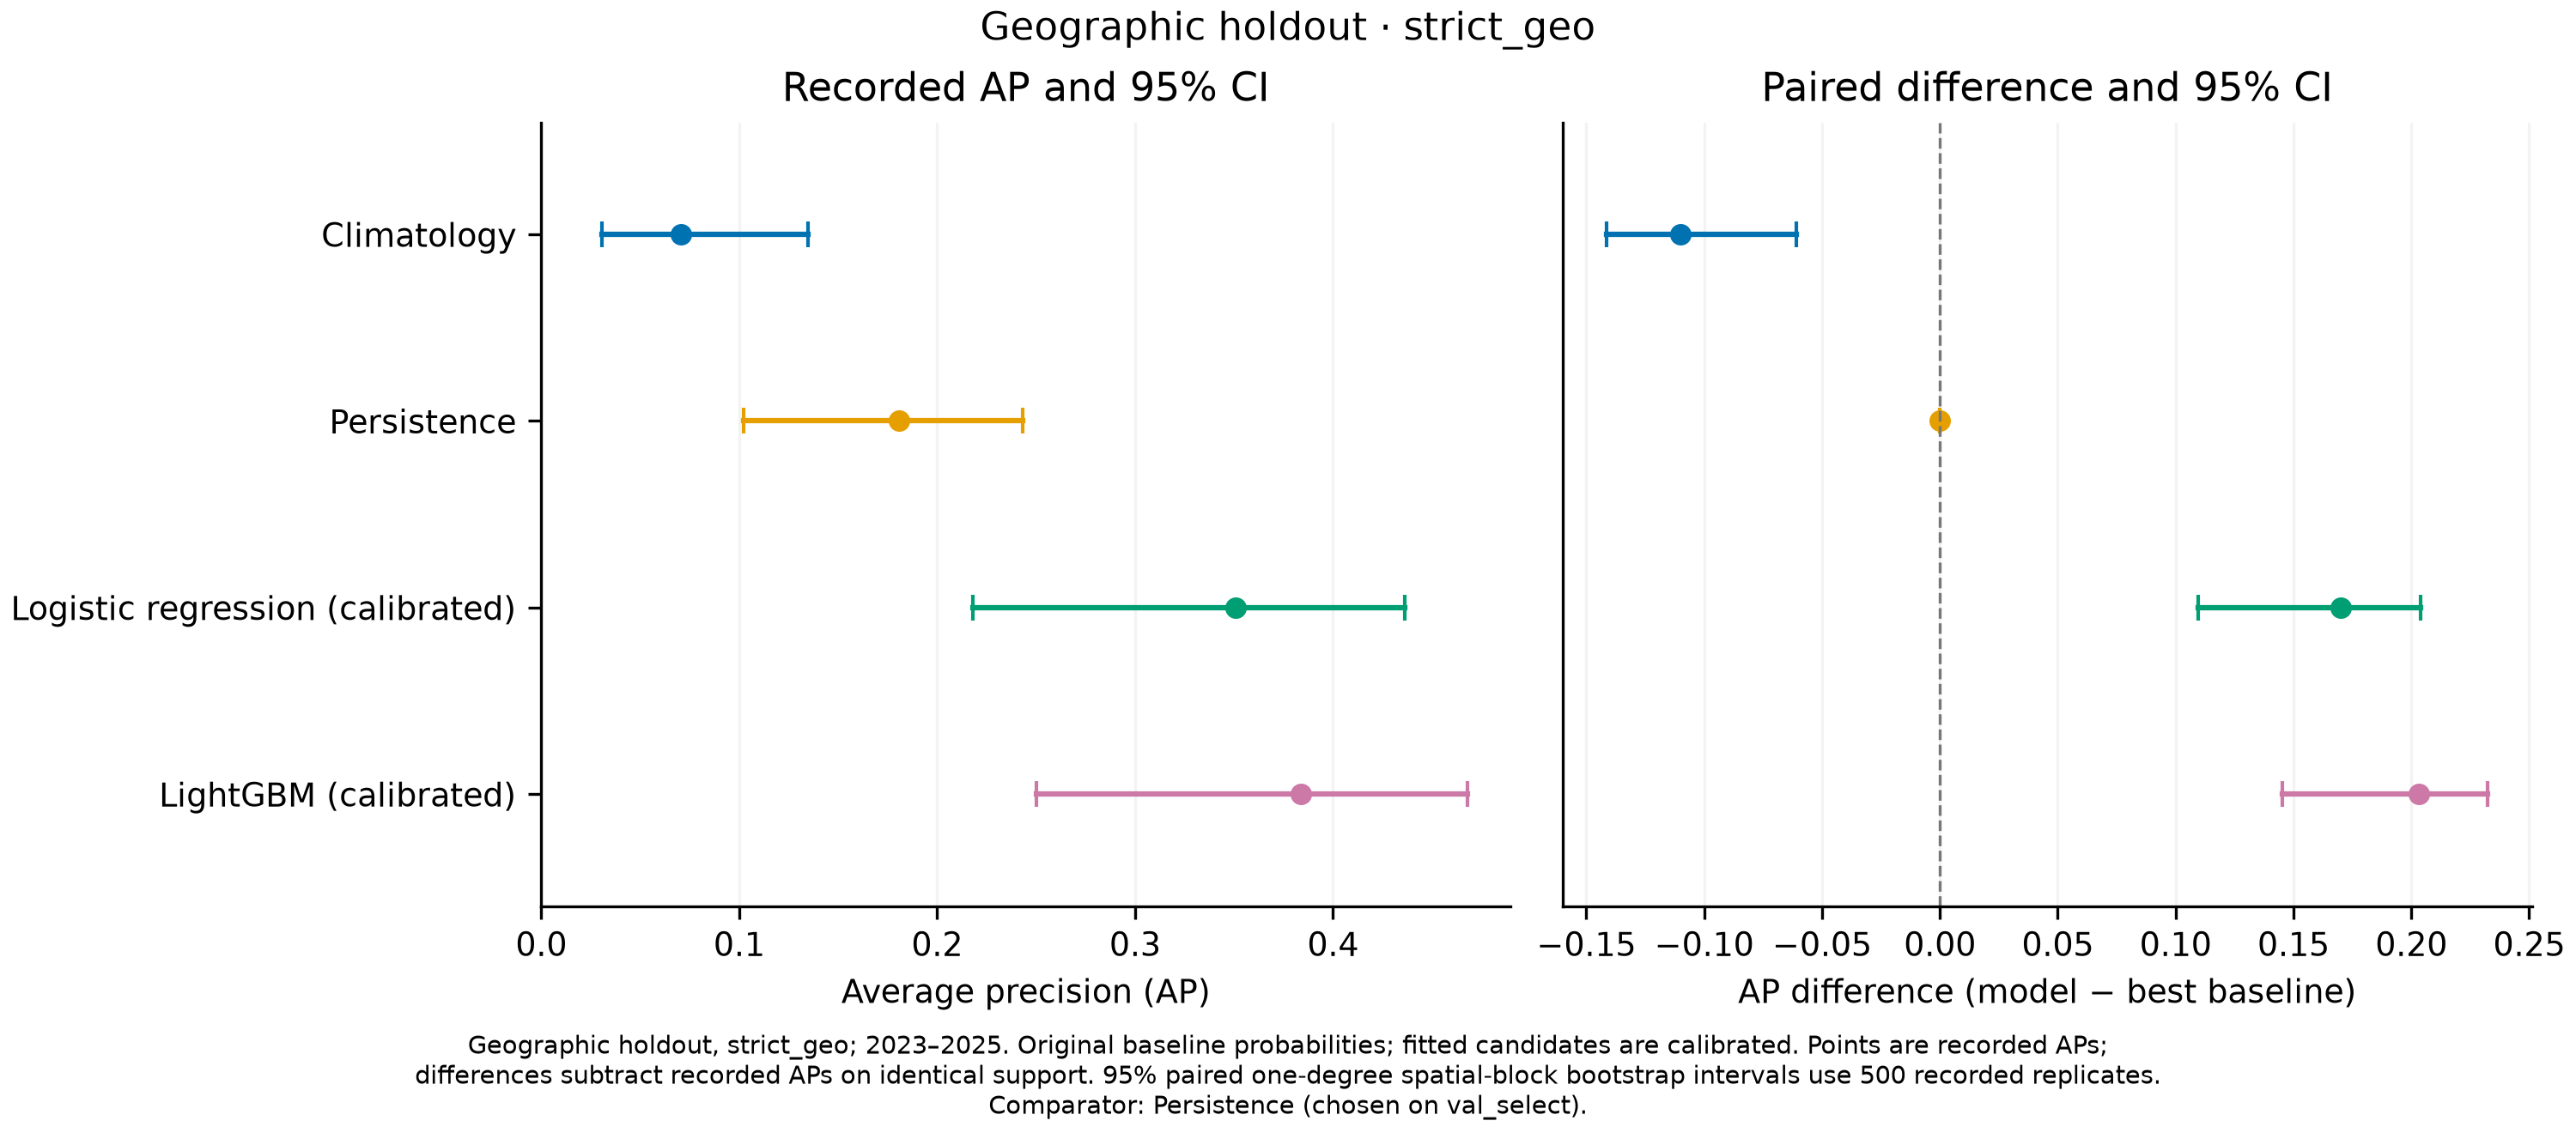

In [6]:
display(Markdown(summary["figures"]["geographic"]["caption"]))
show_results_figure("geographic")

## Recall under weekly area budgets

Recorded recall at 5% and 10% of eligible cell area per issue week. Crossing cells contribute fractionally; positive contributions are pooled over weeks. Original baselines; calibrated fitted candidates.

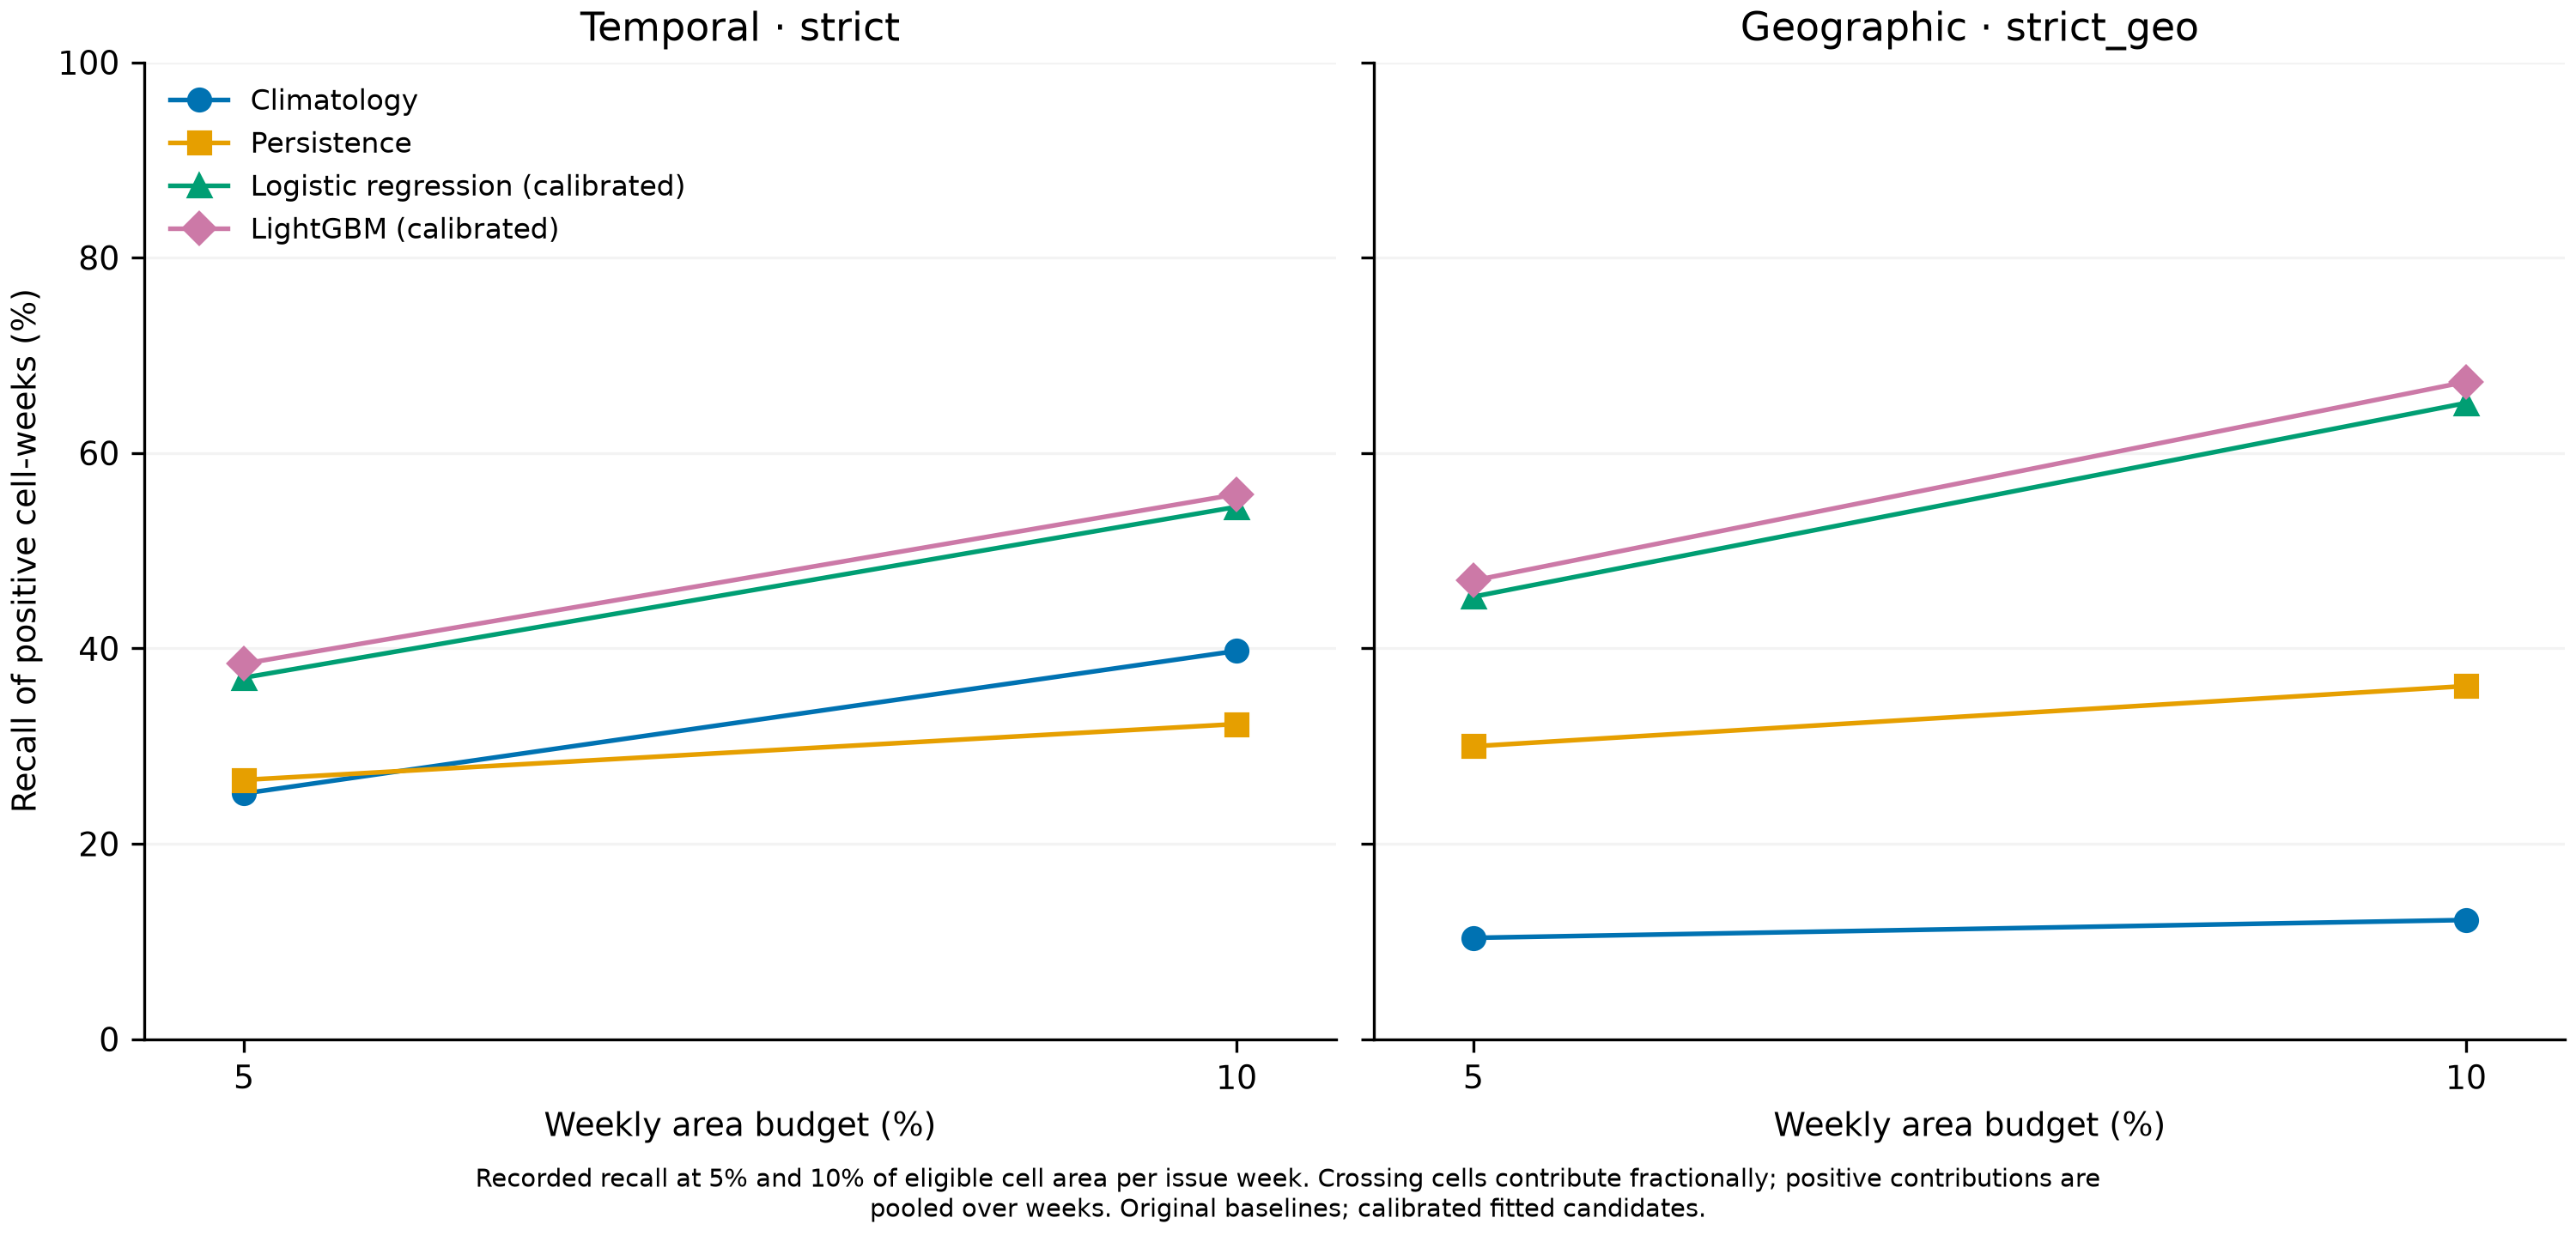

In [7]:
display(Markdown(summary["figures"]["area_budget"]["caption"]))
show_results_figure("area_budget")

## A complete high-activity week in 2024

Issue 2024-09-02, target [2024-09-02, 2024-09-09) UTC. Derived example: largest observed detection total among complete 2024 weeks with national prediction coverage; earliest tie. Calibrated strict predictions outside held-out blocks, strict_geo predictions inside them. Right: observed primary detection count per cell (log1p color scale). ADM1 outlines are pinned boundaries. Week selection and counts are descriptive.

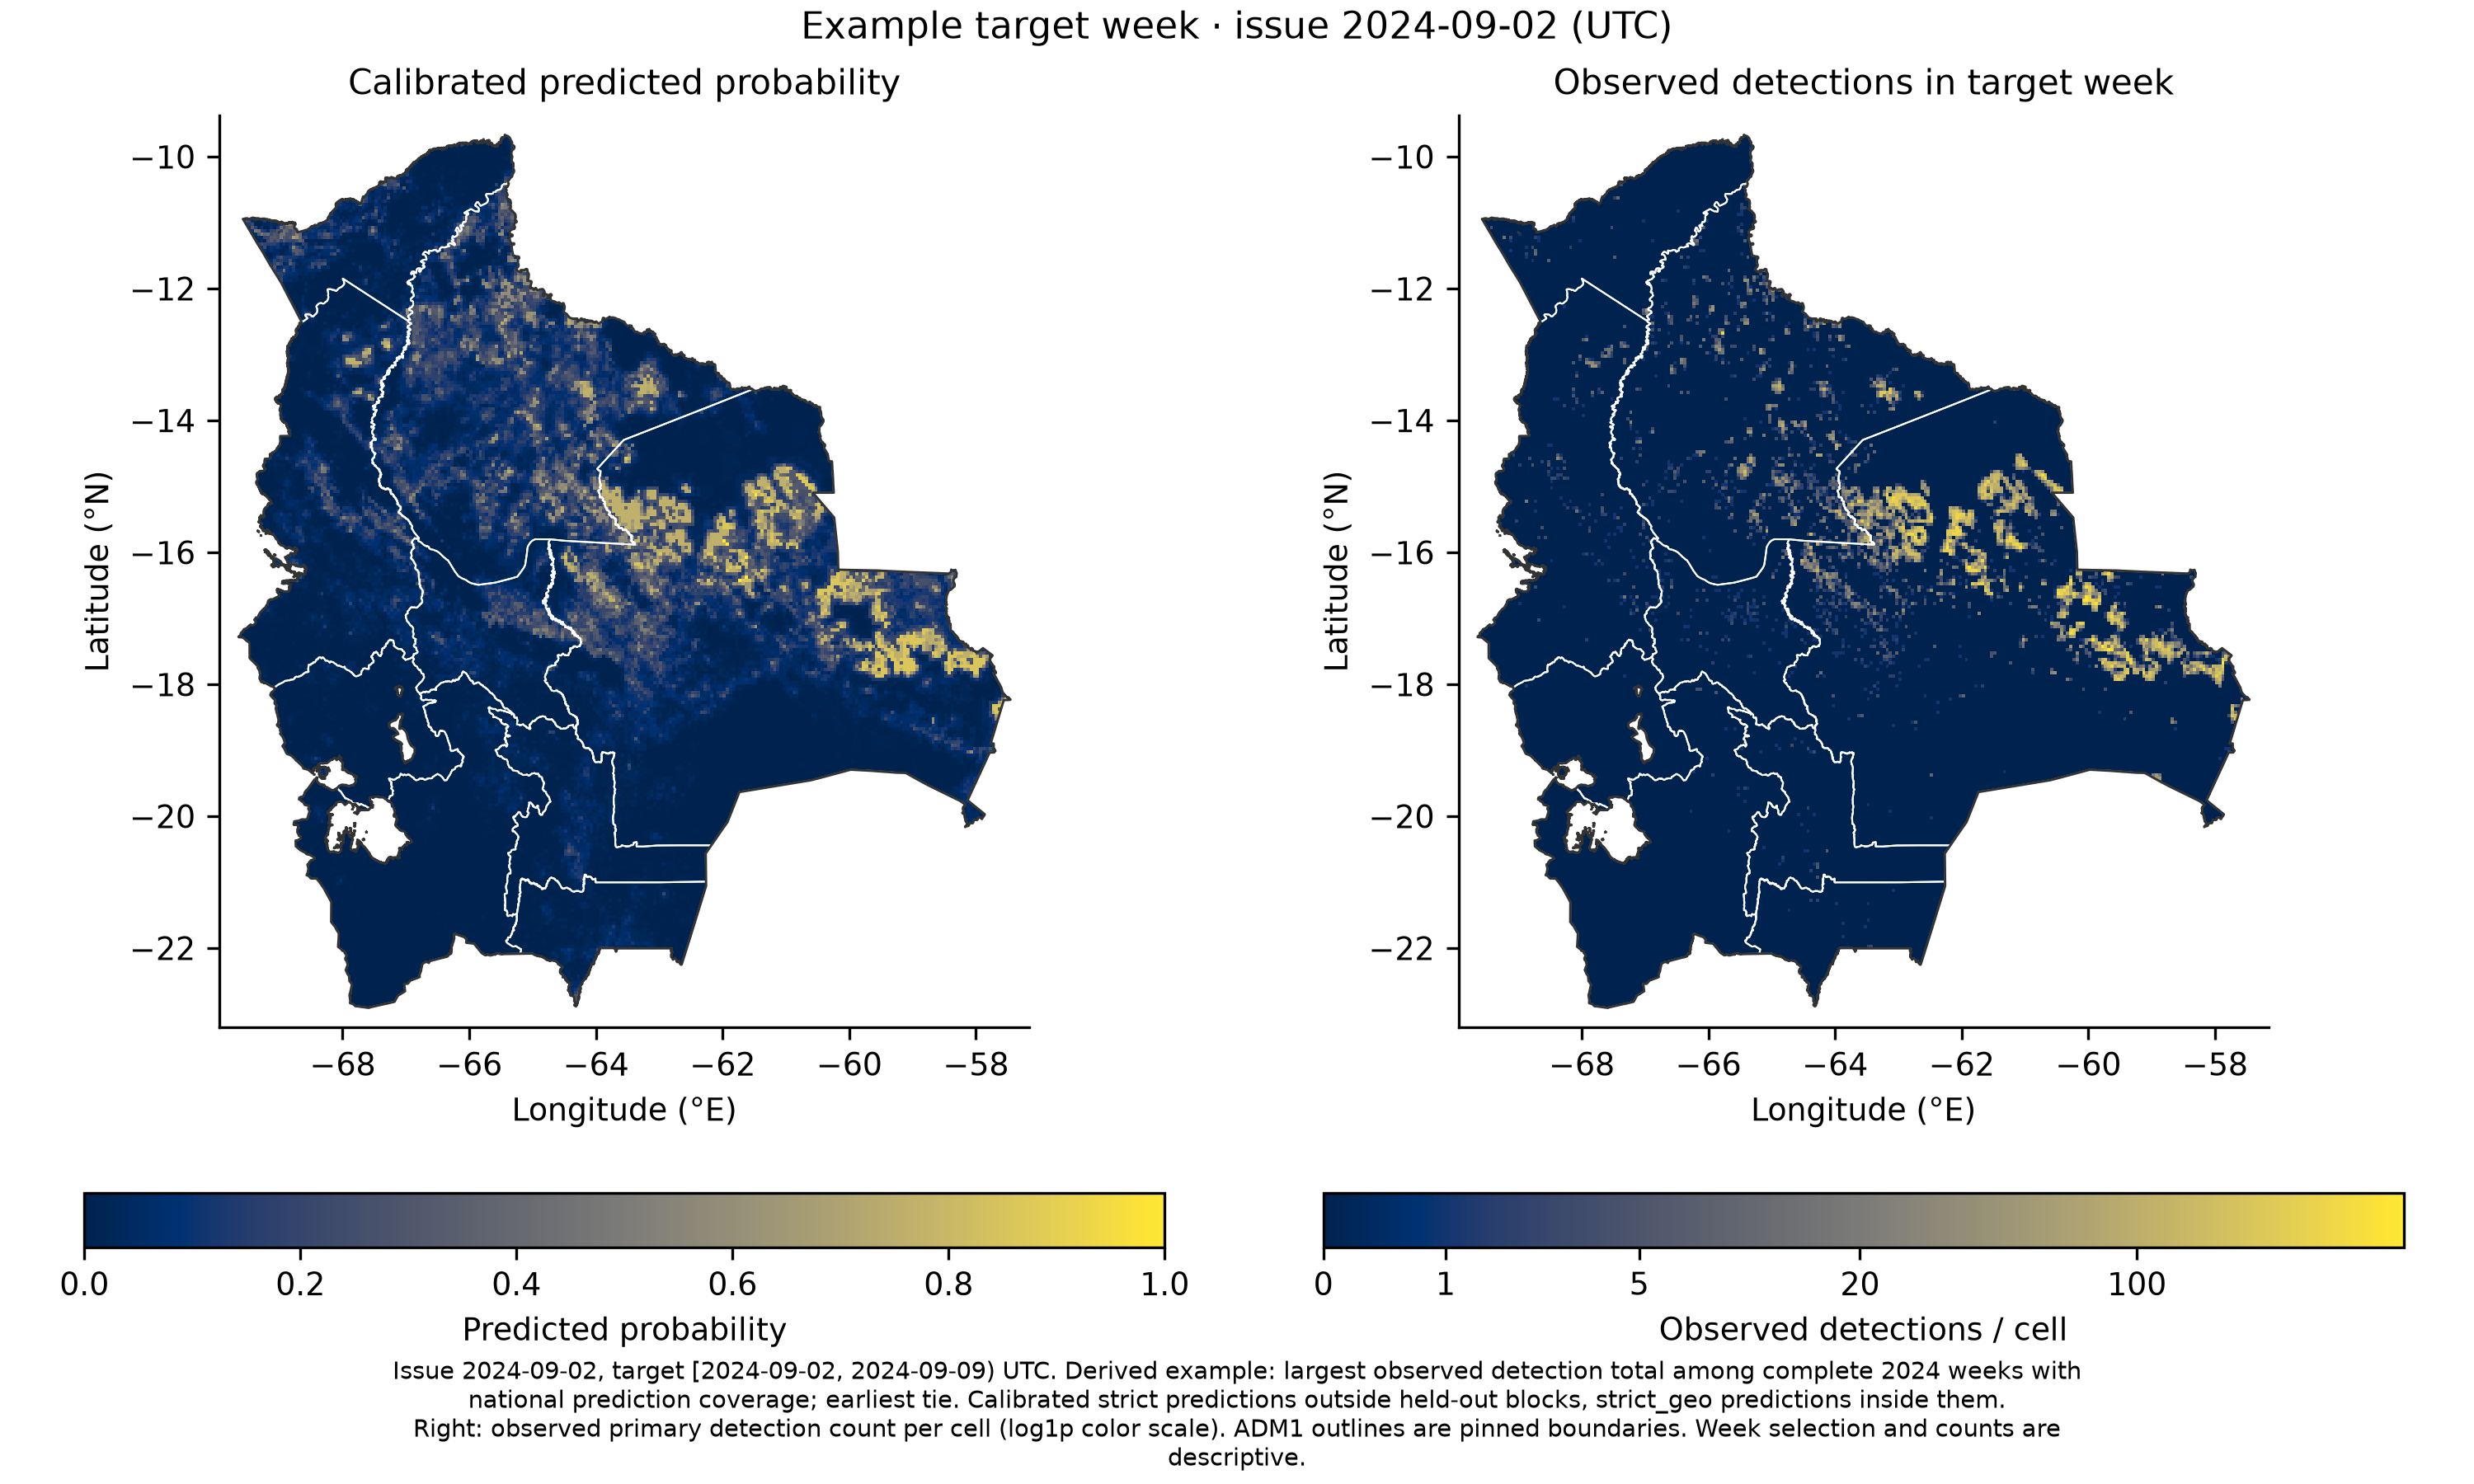

In [8]:
display(Markdown(summary["figures"]["map"]["caption"]))
show_results_figure("map")

## H2: retrospective minus strict AP

H2: retrospective minus strict AP, calibrated selected candidates. The recorded 95% paired month-block interval is shown without a point: the artifact does not record the paired point estimate. The frozen H2 rule tests whether this interval contains zero; it is not an equivalence test.

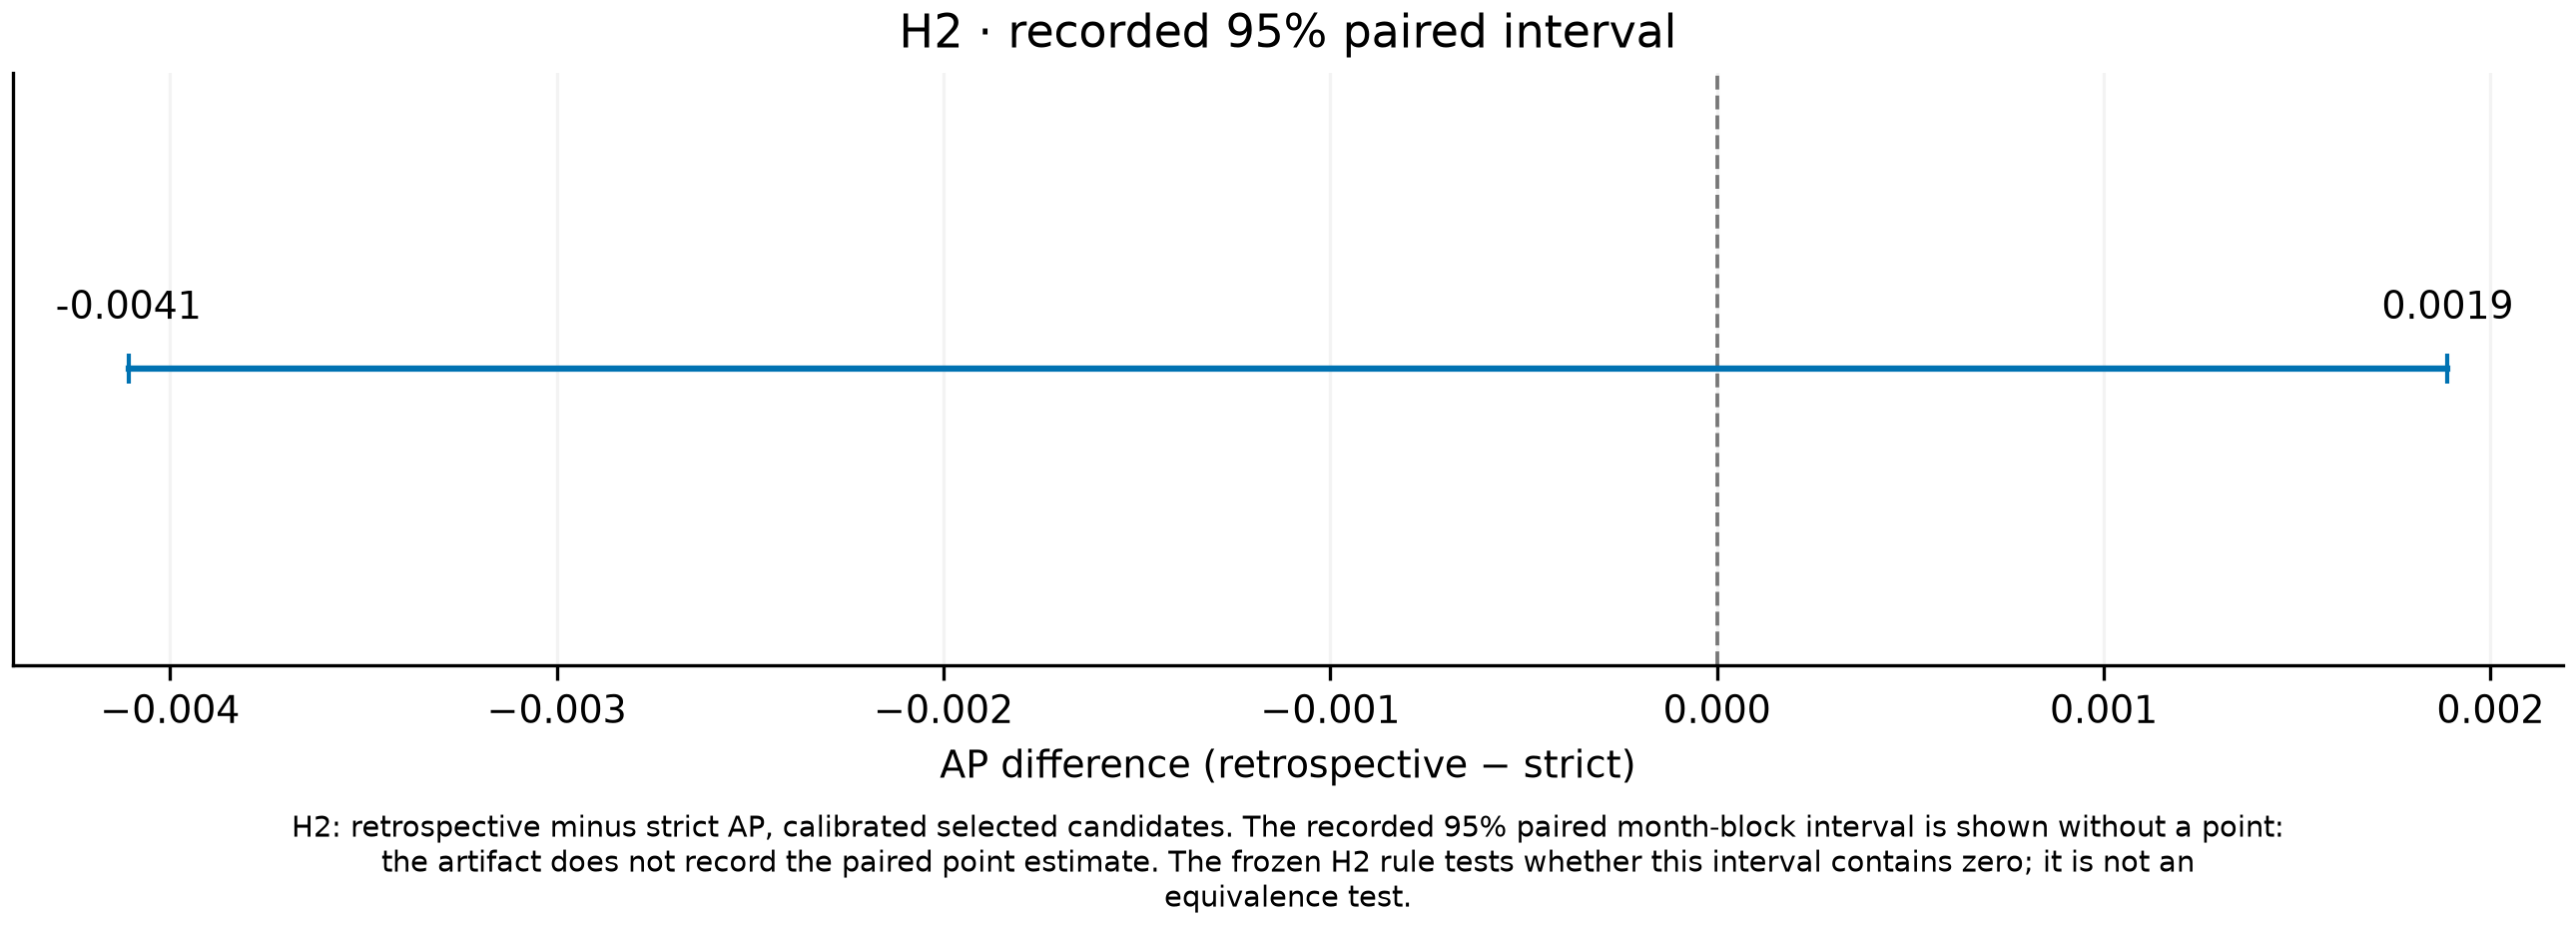

In [9]:
display(Markdown(summary["figures"]["h2"]["caption"]))
show_results_figure("h2")

The H2 artifact contains the paired confidence interval but no paired point estimate, so the interval is shown alone. A confidence interval containing zero satisfies the frozen H2 decision rule; this does not establish equivalence.

The map combines the selected temporal model outside held-out blocks and the selected geographic model inside them. Its week is chosen descriptively from complete 2024 weeks with national prediction coverage, maximizing the panel's primary detection count with earliest-date tie breaking. The observed map shows counts per cell; no map-derived performance statistic is reported.

Exports are 300 dpi PNGs in `artifacts/figures/`, with PNG and PDF copies in the ignored `data/figures/`. Plotted values and source hashes are in `artifacts/figures/results_summary.json`.